# Trade-offs between time, cost and CO2

Between two places, which routes are worth choosing when you care about time and cost, or about time and CO2?

A route is a **best trade-off** when no other route is both faster and cheaper. The set of the best trade-offs is the **Pareto front**. This notebook first finds several routes of this front between Glasgow and Athens, with a list of weighted sums. It then finds every route of the front, on five other routes of Europe.

You need scgraph 4.0 or newer, [matplotlib](https://matplotlib.org) for the charts and [folium](https://python-visualization.github.io/folium/) for the map. The first run downloads the network `europe` once (about 34 MB). GitHub does not show the map.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" matplotlib folium
import folium
import matplotlib.pyplot as plt

from scgraph import GeoGraph

# The style of the charts: text in dark grey, a thin grid, no frame at the top and at the right
plt.rcParams.update({
    "text.color": "#333333", "axes.labelcolor": "#333333", "xtick.color": "#333333", "ytick.color": "#333333",
    "axes.edgecolor": "#999999", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.5,
})

## 1. Three metrics

`europe` holds the roads and the railways of Europe, and every sea lane, port and airport of the world. `load_intermediate_nodes=False` gives a smaller download, and straight lines between the nodes on a map.

In [2]:
europe = GeoGraph.load_geograph("europe", load_intermediate_nodes=False)

A **metric** gives each edge a **weight**, under a name. A query by a metric returns the route with the smallest **total** of weights.

`weight_per_km` gives a **weight per km** for each **edge mode** (`road`, `rail`, `sea` or `air`): the weight of 1 km. `class_weight_per_km` gives a **class** of edges its own weight per km: a ferry that carries trucks is a class of `road`, and is slower. `weight_at_hub` adds a weight at a **hub**: a route by sea gets the weight of a port twice, at the port where it starts and at the port where it ends. Only the edges of the edge modes that `weight_at_hub` names get the weight of a hub. A railway also enters a port, so `rail` has its own weight there.

The weights are for one tonne of freight:

| Edge mode or class | Speed (km/h) | Cost (euros per km) | CO2 (kg per km) | At each hub |
|---|---|---|---|---|
| `road` | 70 | 0.10 | 0.10 | |
| `ferry` | 35 | 0.10 | 0.10 | |
| `rail` | 50 | 0.04 | 0.02 | rail terminal or port: 4 hours, 15 euros |
| `sea` | 30 | 0.01 | 0.015 | port: 12 hours, 30 euros |
| `air` | 750 | 0.50 | 0.60 | airport: 4 hours, 50 euros |

These weights are examples: scgraph ships no speed, no cost and no emission factor. Replace them with your own.

In [3]:
def create_metrics(geograph):
    """Create the metrics hours, euros and kg_co2 of a network."""
    # off_graph_weight_per_km is the weight per km of the off-graph legs: the straight lines between the two places of a query and the network
    geograph.create_metric(
        "hours",
        weight_per_km={"road": 1 / 70, "rail": 1 / 50, "sea": 1 / 30, "air": 1 / 750},
        off_graph_weight_per_km=1 / 30,
        class_weight_per_km={"ferry": 1 / 35},
        weight_at_hub={"rail_terminal": {"rail": 4}, "port": {"sea": 12, "rail": 4}, "airport": {"air": 4}},
    )
    geograph.create_metric(
        "euros",
        weight_per_km={"road": 0.10, "rail": 0.04, "sea": 0.01, "air": 0.50},
        off_graph_weight_per_km=0.10,
        weight_at_hub={"rail_terminal": {"rail": 15}, "port": {"sea": 30, "rail": 15}, "airport": {"air": 50}},
    )
    geograph.create_metric("kg_co2", weight_per_km={"road": 0.10, "rail": 0.02, "sea": 0.015, "air": 0.60}, off_graph_weight_per_km=0.10)


create_metrics(europe)
print([metric["name"] for metric in europe.metrics])

['length', 'hours', 'euros', 'kg_co2']


## 2. The best route for each metric

`output_legs=True` returns the **legs** of a route: a leg is a part of a route on one edge mode. Look at the last column: each metric chooses other edge modes.

In [4]:
GLASGOW = {"latitude": 55.8642, "longitude": -4.2518}
ATHENS = {"latitude": 37.9838, "longitude": 23.7275}

print(f"{'Best for':<9}{'km':>7}{'hours':>8}{'euros':>8}{'kg CO2':>8}   Edge modes of the legs")
for metric in ["hours", "euros", "kg_co2"]:
    route = europe.get_shortest_path(origin_node=GLASGOW, destination_node=ATHENS, metric=metric, output_legs=True)
    totals = "".join(f"{route['metric_totals'][name]:>8,.0f}" for name in ["hours", "euros", "kg_co2"])
    leg_modes = " + ".join(leg["edge_mode"] for leg in route["legs"][1:-1])
    print(f"{metric:<9}{route['length']:>7,.0f}{totals}   {leg_modes}")

Best for      km   hours   euros  kg CO2   Edge modes of the legs
hours      2,945      13   1,534   1,718   road + air + road


euros      5,263     199     115      81   road + sea + road


kg_co2     3,395     160     254      59   road + rail + sea + rail + sea + road


## 3. A sweep for hours against euros

A **weighted sum** is a metric that adds other metrics, each one times a **coefficient**. The metric `score` adds the euros and the hours times the coefficient: with a coefficient of 20, one hour is worth 20 euros.

With a small coefficient, the best route by `score` is cheap. With a large coefficient, it is fast. A **sweep** tries a list of coefficients and keeps the distinct routes.

In [5]:
def add_modes(route):
    """Give a route its `modes` (the edge modes of its legs, each one once) and its `main_mode` (the edge mode of its longest leg)."""
    legs = route["legs"][1:-1]  # without the two straight lines at the ends
    route["modes"] = " + ".join(dict.fromkeys(leg["edge_mode"] for leg in legs))
    route["main_mode"] = max(legs, key=lambda leg: leg["length"])["edge_mode"]


def find_trade_offs(geograph, origin, destination, metric_x, metric_y, coefficients):
    """The distinct routes of a sweep, sorted by their total of `metric_x`.

    For each coefficient, the sweep finds the route with the smallest total of
    coefficient * metric_x + metric_y. Two routes are the same when their two totals,
    rounded to a whole number, are equal. Each route gets its `modes` and its `main_mode`.
    """
    routes = {}
    for coefficient in coefficients:
        geograph.create_metric("score", weighted_sum_of={metric_x: coefficient, metric_y: 1})
        route = geograph.get_shortest_path(origin_node=origin, destination_node=destination, metric="score", output_legs=True)
        add_modes(route)
        totals = (round(route["metric_totals"][metric_x]), round(route["metric_totals"][metric_y]))
        routes.setdefault(totals, route)
    geograph.remove_metric("score")
    return [routes[totals] for totals in sorted(routes)]

Each coefficient is twice the one before. The routes are printed from the fastest to the cheapest. Each route of a sweep is a best trade-off: a route both faster and cheaper would have a smaller score for every coefficient.

In [6]:
COEFFICIENTS = [0.1 * 2**step for step in range(13)]  # 0.1, 0.2, 0.4, ... 409.6

fronts = {"euros": find_trade_offs(europe, GLASGOW, ATHENS, "hours", "euros", COEFFICIENTS)}
for route in fronts["euros"]:
    print(f"{route['metric_totals']['hours']:>5.0f} hours{route['metric_totals']['euros']:>7.0f} euros   {route['modes']}")

   13 hours   1534 euros   road + air
   53 hours    347 euros   road
   85 hours    186 euros   road + rail
  199 hours    115 euros   road + sea


## 4. A sweep for hours against kg of CO2

Here the coefficient is the count of kg of CO2 that one hour is worth.

In [7]:
fronts["kg_co2"] = find_trade_offs(europe, GLASGOW, ATHENS, "hours", "kg_co2", COEFFICIENTS)
for route in fronts["kg_co2"]:
    print(f"{route['metric_totals']['hours']:>5.0f} hours{route['metric_totals']['kg_co2']:>7.0f} kg   {route['modes']}")

   13 hours   1718 kg   road + air
   53 hours    347 kg   road
   77 hours    131 kg   road + rail
   85 hours     79 kg   road + rail
  116 hours     65 kg   road + rail + sea
  159 hours     59 kg   road + rail + sea


## 5. The two fronts on charts

Each point is a route: the text beside it names its edge modes, and its color is the edge mode of its longest leg. A step line joins the points. Look at each front: the fastest route is far above the others.

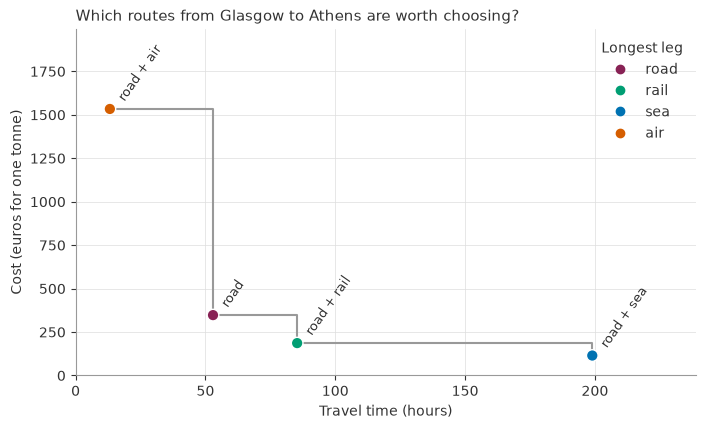

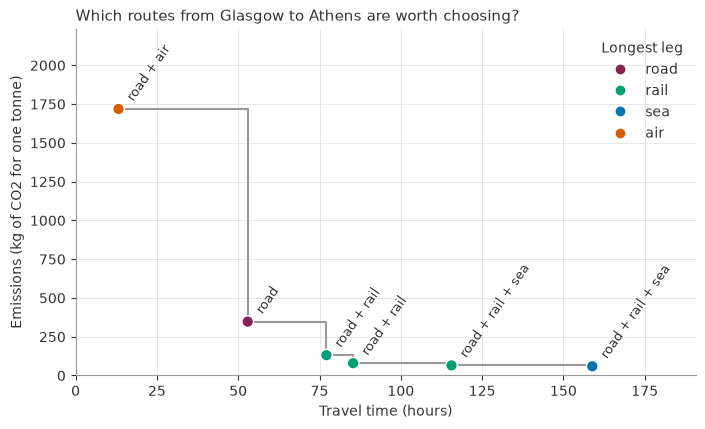

In [8]:
COLORS = {"road": "#882255", "rail": "#009E73", "sea": "#0072B2", "air": "#D55E00"}
AXIS_LABELS = {"euros": "Cost (euros for one tonne)", "kg_co2": "Emissions (kg of CO2 for one tonne)"}
color_key = [plt.Line2D([], [], marker="o", linestyle="", color=color, label=mode) for mode, color in COLORS.items()]

for metric_y, routes in fronts.items():
    hours = [route["metric_totals"]["hours"] for route in routes]
    totals = [route["metric_totals"][metric_y] for route in routes]
    figure, ax = plt.subplots(figsize=(8, 4.5))
    ax.step(hours, totals, where="post", color="#999999", linewidth=1.5, zorder=1)
    ax.scatter(hours, totals, s=70, color=[COLORS[route["main_mode"]] for route in routes], edgecolor="white", zorder=2)
    for route, x, y in zip(routes, hours, totals):
        ax.annotate(route["modes"], (x, y), xytext=(4, 6), textcoords="offset points", rotation=55, fontsize=9)
    ax.set(xlim=(0, 1.2 * max(hours)), ylim=(0, 1.3 * max(totals)))
    ax.set(xlabel="Travel time (hours)", ylabel=AXIS_LABELS[metric_y])
    ax.set_title("Which routes from Glasgow to Athens are worth choosing?", loc="left", fontsize=11)
    ax.legend(handles=color_key, title="Longest leg", frameon=False)
    plt.show()

## 6. The routes on a map

The map draws the routes of the first sweep in the same colors. Move the pointer over a line to read its route.

In [9]:
route_map = folium.Map(location=[47, 10], zoom_start=4)
for route in fronts["euros"]:
    tooltip = f"{route['modes']}: {route['metric_totals']['hours']:.0f} hours, {route['metric_totals']['euros']:.0f} euros"
    for leg in route["legs"]:
        color = COLORS.get(leg["edge_mode"], "#555555")  # grey for the two straight lines at the ends
        folium.PolyLine(leg["coordinate_path"], color=color, tooltip=tooltip).add_to(route_map)
route_map

## 7. What the sweep finds, and what it misses

A sweep does not find every best trade-off. The drawing shows the first sweep again, without its fastest route.

- A route above the **step line** is worse than a route of the sweep on both metrics.
- The **dashed line** joins the routes of the sweep. A route under it can be the best for some coefficient: more coefficients can find it.
- A route in a **grey triangle** can be a best trade-off, but it is the best for no coefficient: one of the two corners always has a smaller score. More coefficients do not find it.

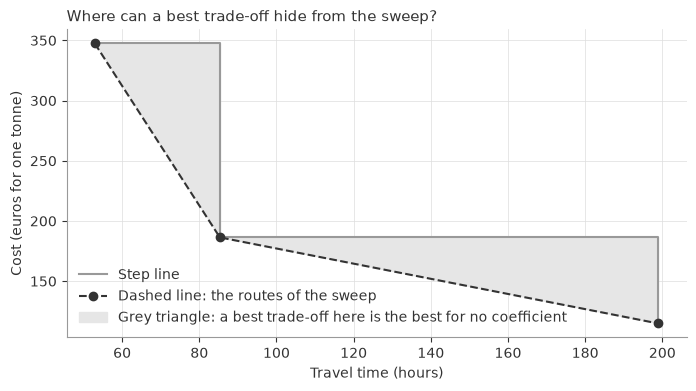

In [10]:
routes = fronts["euros"][1:]  # without the fastest route, to show the other routes larger
hours = [route["metric_totals"]["hours"] for route in routes]
euros = [route["metric_totals"]["euros"] for route in routes]

figure, ax = plt.subplots(figsize=(8, 4))
for x_a, y_a, x_b, y_b in zip(hours, euros, hours[1:], euros[1:]):
    ax.fill([x_a, x_b, x_b], [y_a, y_a, y_b], color="#E6E6E6")
ax.step(hours, euros, where="post", color="#999999", linewidth=1.5, label="Step line")
ax.plot(hours, euros, "o--", color="#333333", linewidth=1.5, label="Dashed line: the routes of the sweep")
ax.fill([], [], color="#E6E6E6", label="Grey triangle: a best trade-off here is the best for no coefficient")
ax.set(xlabel="Travel time (hours)", ylabel=AXIS_LABELS["euros"])
ax.set_title("Where can a best trade-off hide from the sweep?", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.show()

The sweep finds only the best trade-offs on the **convex hull** of the front. To draw the convex hull, join by straight segments the routes that a sweep can find, for every coefficient. Every best trade-off is on the convex hull or above it. The dashed line above is the convex hull of the routes of one sweep only: more coefficients can move it down. A best trade-off above the convex hull needs a search that keeps several totals at each node: `get_pareto_paths` runs this search.

## 8. The exact front and the approximate front

A sweep gives an **approximate front**: the routes that a weighted sum of the two metrics finds, for some coefficient. `get_pareto_paths` gives the **exact front**: every route that no other route beats on both metrics at once. Each route of the exact front is a **Pareto path**.

A sweep cannot find a route above the convex hull, whatever its coefficients. For one coefficient, the routes with the same score `coefficient * hours + kg` lie on a straight line of the chart. The best route by the score is the first route that this line touches when it moves up from below, so it is always a corner of the convex hull. A route above the convex hull lies above the segment between two corners, and one of these two corners has a smaller score for every coefficient.

The five routes below compare the two fronts on time and CO2. Under each chart, the notebook prints how many routes the sweep misses, and how many of them no coefficient can find. Each route shows another case:

| Route | What it shows |
|---|---|
| Paris to Istanbul | The route of the Orient Express: by rail alone, or by rail and sea |
| London to Paris | The crossing of the Channel: road, rail and sea give routes that the sweep misses |
| Stockholm to Helsinki | A flight is the fastest and emits the most. A ship is the slowest and emits the least |
| Barcelona to Rome | All four edge modes are on the front |
| Lisbon to Madrid | The two fronts are the same |

In [11]:
CITIES = {
    "Paris": {"latitude": 48.8566, "longitude": 2.3522},
    "Istanbul": {"latitude": 41.0082, "longitude": 28.9784},
    "London": {"latitude": 51.5074, "longitude": -0.1278},
    "Stockholm": {"latitude": 59.3293, "longitude": 18.0686},
    "Helsinki": {"latitude": 60.1699, "longitude": 24.9384},
    "Barcelona": {"latitude": 41.3874, "longitude": 2.1686},
    "Rome": {"latitude": 41.9028, "longitude": 12.4964},
    "Lisbon": {"latitude": 38.7223, "longitude": -9.1393},
    "Madrid": {"latitude": 40.4168, "longitude": -3.7038},
}
AXIS_LABELS["hours"] = "Travel time (hours)"


def get_hours_and_kg(route):
    """The hours and the kg of CO2 of a route, rounded to compare the routes of two searches."""
    return round(route["metric_totals"]["hours"], 6), round(route["metric_totals"]["kg_co2"], 6)


def mark_convex_hull(routes):
    """Give each route of a front `is_on_convex_hull`. The routes are sorted from the fastest."""
    hull = []
    for route in routes:
        route["is_on_convex_hull"] = True
        hours, kg = get_hours_and_kg(route)
        while len(hull) >= 2:
            (hours_before, kg_before), (hours_last, kg_last) = get_hours_and_kg(hull[-2]), get_hours_and_kg(hull[-1])
            # The last route stays when it is under the segment from the route before it to the new route
            if (hours_last - hours_before) * (kg - kg_before) > (kg_last - kg_before) * (hours - hours_before):
                break
            hull.pop()["is_on_convex_hull"] = False
        hull.append(route)


def compare_fronts(geograph, origin, destination):
    """Draw the exact front and the approximate front between two cities, on hours and kg of CO2.

    Print the difference between the two fronts, and return the routes of the exact front.
    Each route gets `is_approximate`: whether a route of the sweep has the same two totals.
    """
    exact = geograph.get_pareto_paths(CITIES[origin], CITIES[destination], ["hours", "kg_co2"], output_legs=True)
    approximate = find_trade_offs(geograph, CITIES[origin], CITIES[destination], "hours", "kg_co2", COEFFICIENTS)
    swept_totals = {get_hours_and_kg(route) for route in approximate}
    mark_convex_hull(exact)
    for route in exact:
        add_modes(route)
        route["is_approximate"] = get_hours_and_kg(route) in swept_totals
    only_exact = [route for route in exact if not route["is_approximate"]]

    figure, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(*zip(*map(get_hours_and_kg, approximate)), "--", color="#333333", linewidth=1, zorder=1)
    ax.scatter(*zip(*map(get_hours_and_kg, approximate)), s=80, marker="o", edgecolor="#333333", zorder=3,
               color=[COLORS[route["main_mode"]] for route in approximate], label="Approximate front (and exact front)")
    if only_exact:
        ax.scatter(*zip(*map(get_hours_and_kg, only_exact)), s=40, marker="^", facecolor="white", linewidth=1.5, zorder=2,
                   edgecolor=[COLORS[route["main_mode"]] for route in only_exact], label="Exact front only")
    ax.set(xlabel=AXIS_LABELS["hours"], ylabel=AXIS_LABELS["kg_co2"], ylim=(0, None))
    ax.set_title(f"{origin} to {destination}: the color is the edge mode of the longest leg", loc="left", fontsize=11)
    ax.legend(handles=[*ax.get_legend_handles_labels()[0], *color_key], frameon=False)
    plt.show()

    above_hull_count = sum(not route["is_on_convex_hull"] for route in exact)
    print(f"Exact front: {len(exact)} routes. Approximate front: {len(approximate)} routes. The sweep misses {len(only_exact)} routes.")
    print(f"{above_hull_count} routes of the exact front are above its convex hull: no coefficient finds them.")
    print("Edge modes on the exact front:", ", ".join(sorted({route["modes"] for route in exact})))
    # Of the routes that the sweep misses, the one that saves the most against its two neighbours of the approximate front
    best_saving, best = 0, None
    for route in only_exact:
        hours, kg = get_hours_and_kg(route)
        faster_routes = [other for other in approximate if other["metric_totals"]["hours"] < hours]
        slower_routes = [other for other in approximate if other["metric_totals"]["hours"] > hours]
        if faster_routes and slower_routes:
            faster, slower = faster_routes[-1], slower_routes[0]
            saving = min(1 - kg / faster["metric_totals"]["kg_co2"], 1 - hours / slower["metric_totals"]["hours"])
            if saving > best_saving:
                best_saving, best = saving, (route, faster, slower)
    if best is None:
        print("No route of the exact front lies between two routes of the approximate front.")
    else:
        route, faster, slower = best
        hours, kg = get_hours_and_kg(route)
        print(f"A route that the sweep misses, by {route['modes']}: {hours:.1f} hours and {kg:.0f} kg of CO2.")
        print(f"  Against the faster route by {faster['modes']}: {hours - faster['metric_totals']['hours']:.1f} hours more, "
              f"{faster['metric_totals']['kg_co2'] - kg:.0f} kg of CO2 less.")
        print(f"  Against the slower route by {slower['modes']}: {slower['metric_totals']['hours'] - hours:.1f} hours less, "
              f"{kg - slower['metric_totals']['kg_co2']:.0f} kg of CO2 more.")
    return exact

### Paris to Istanbul

The Orient Express ran from Paris to Istanbul. This route is too long for an exact search on the whole network `europe`. The search keeps several partial routes at every node, and the roads hold most of the nodes of `europe`. The search then stops with a `MemoryError`, at the limit that its argument `max_labels` sets.

So this route uses `europe` without the node mode `road`: railways, sea lanes, ports, airports and rail terminals. In `europe`, an airport joins the rest of the network by road only. So no route reaches an airport here, and this front has no flight.

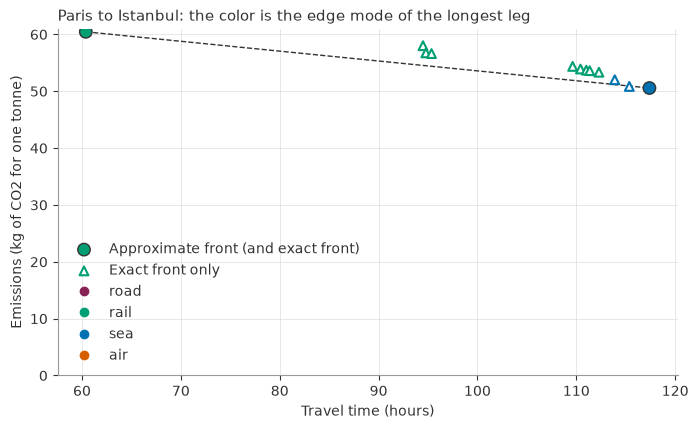

Exact front: 12 routes. Approximate front: 2 routes. The sweep misses 10 routes.
9 routes of the exact front are above its convex hull: no coefficient finds them.
Edge modes on the exact front: rail, rail + sea
A route that the sweep misses, by rail + sea: 109.6 hours and 54 kg of CO2.
  Against the faster route by rail: 49.2 hours more, 6 kg of CO2 less.
  Against the slower route by rail + sea: 7.8 hours less, 4 kg of CO2 more.


In [12]:
rail_and_sea = GeoGraph.load_geograph("europe", load_intermediate_nodes=False, node_modes=["rail", "sea", "port", "airport", "rail_terminal"])
create_metrics(rail_and_sea)
exact_fronts = {"Paris to Istanbul": compare_fronts(rail_and_sea, "Paris", "Istanbul")}

### London to Paris

The four other routes are short enough for the whole network `europe`, with its roads and its flights. From London to Paris, a route crosses the Channel by road, by rail or by sea.

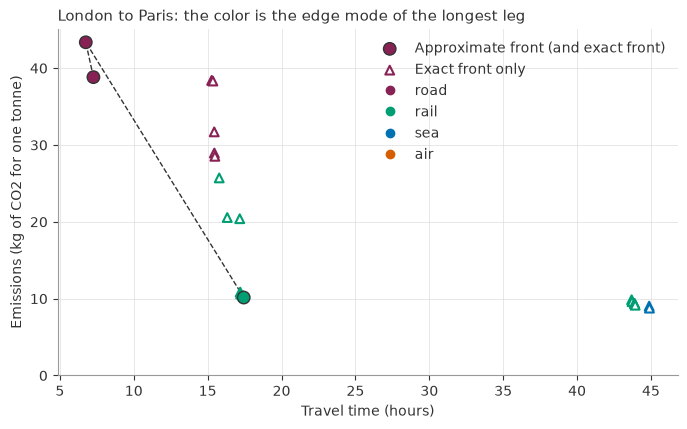

Exact front: 22 routes. Approximate front: 3 routes. The sweep misses 19 routes.
17 routes of the exact front are above its convex hull: no coefficient finds them.
Edge modes on the exact front: road, road + rail, road + sea + rail
A route that the sweep misses, by road + rail: 15.4 hours and 38 kg of CO2.
  Against the faster route by road: 8.6 hours more, 5 kg of CO2 less.
  Against the slower route by road + rail: 2.1 hours less, 28 kg of CO2 more.


In [13]:
exact_fronts["London to Paris"] = compare_fronts(europe, "London", "Paris")

### Stockholm to Helsinki

A flight crosses the Baltic Sea in a short time and emits the most. A ship takes longer and emits the least.

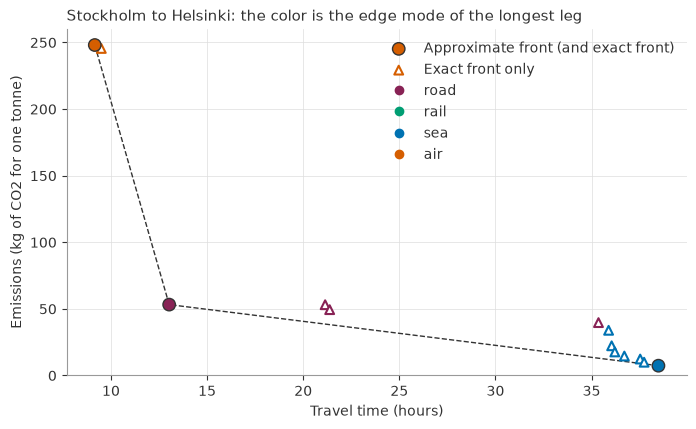

Exact front: 13 routes. Approximate front: 3 routes. The sweep misses 10 routes.
10 routes of the exact front are above its convex hull: no coefficient finds them.
Edge modes on the exact front: road, road + air, road + rail, road + sea
A route that the sweep misses, by road + sea: 35.4 hours and 40 kg of CO2.
  Against the faster route by road: 22.3 hours more, 14 kg of CO2 less.
  Against the slower route by road + sea: 3.1 hours less, 32 kg of CO2 more.


In [14]:
exact_fronts["Stockholm to Helsinki"] = compare_fronts(europe, "Stockholm", "Helsinki")

### Barcelona to Rome

A route by road, by rail, by sea or by air: each edge mode has routes on the front.

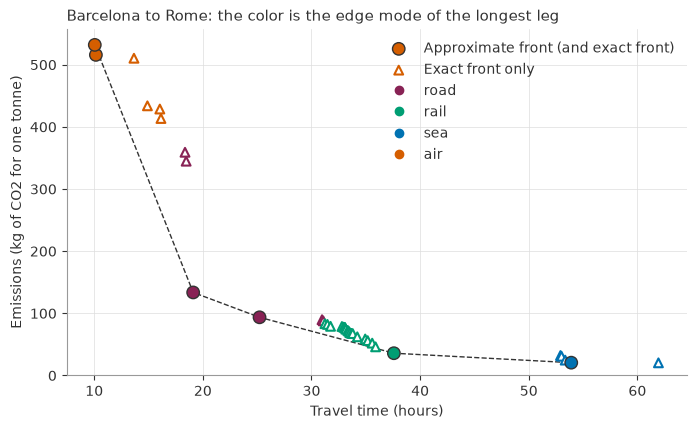

Exact front: 36 routes. Approximate front: 6 routes. The sweep misses 30 routes.
29 routes of the exact front are above its convex hull: no coefficient finds them.
Edge modes on the exact front: road, road + air, road + rail, road + rail + sea, road + sea
A route that the sweep misses, by road + air: 14.9 hours and 434 kg of CO2.
  Against the faster route by road + air: 4.8 hours more, 98 kg of CO2 less.
  Against the slower route by road: 4.2 hours less, 300 kg of CO2 more.


In [15]:
exact_fronts["Barcelona to Rome"] = compare_fronts(europe, "Barcelona", "Rome")

### Lisbon to Madrid

Here the exact front has few routes, and each one is a corner of the convex hull. So the sweep finds them all.

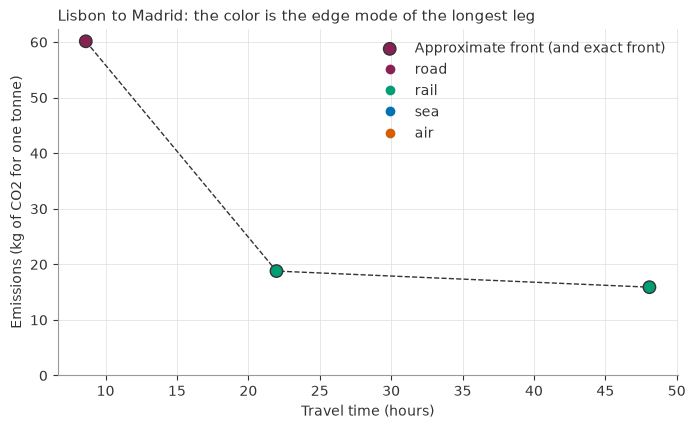

Exact front: 3 routes. Approximate front: 3 routes. The sweep misses 0 routes.
0 routes of the exact front are above its convex hull: no coefficient finds them.
Edge modes on the exact front: road, road + rail, road + sea + rail
No route of the exact front lies between two routes of the approximate front.


In [16]:
exact_fronts["Lisbon to Madrid"] = compare_fronts(europe, "Lisbon", "Madrid")

### The routes that the sweep misses, on a map

The map draws routes from Barcelona to Rome that only the exact front has: for each combination of edge modes, the fastest one. Move the pointer over a line to read its route.

In [17]:
route_map = folium.Map(location=[42, 7], zoom_start=5)
missed = {}
for route in exact_fronts["Barcelona to Rome"]:
    if not route["is_approximate"]:
        missed.setdefault(route["modes"], route)  # the routes are sorted from the fastest
for route in missed.values():
    tooltip = f"{route['modes']}: {route['metric_totals']['hours']:.0f} hours, {route['metric_totals']['kg_co2']:.0f} kg of CO2"
    for leg in route["legs"]:
        color = COLORS.get(leg["edge_mode"], "#555555")  # grey for the two straight lines at the ends
        folium.PolyLine(leg["coordinate_path"], color=color, weight=2, tooltip=tooltip).add_to(route_map)
route_map

## 9. A third metric

`get_pareto_paths` takes two metrics or more. With the euros as a third metric, a route that is slower and emits more can stay on the exact front because it is cheaper. The chart shows the routes from Barcelona to Rome on time and CO2, and the color gives their euros.

Exact front with two metrics: 36 routes. With three metrics: 39 routes.


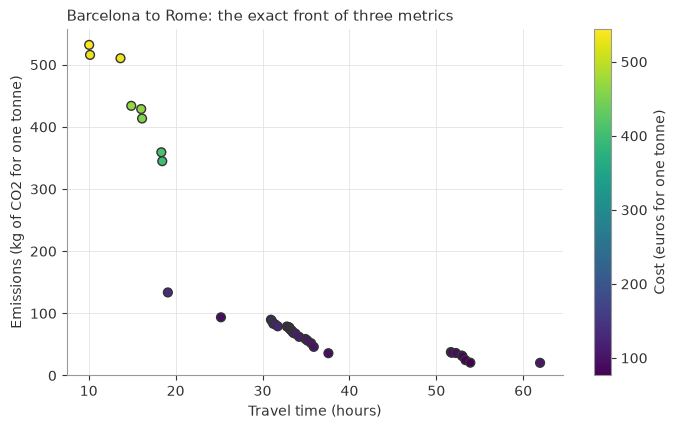

In [18]:
two_metrics = exact_fronts["Barcelona to Rome"]
three_metrics = europe.get_pareto_paths(CITIES["Barcelona"], CITIES["Rome"], ["hours", "kg_co2", "euros"])
print(f"Exact front with two metrics: {len(two_metrics)} routes. With three metrics: {len(three_metrics)} routes.")

figure, ax = plt.subplots(figsize=(8, 4.5))
points = ax.scatter([route["metric_totals"]["hours"] for route in three_metrics], [route["metric_totals"]["kg_co2"] for route in three_metrics],
                    c=[route["metric_totals"]["euros"] for route in three_metrics], cmap="viridis", s=40, edgecolor="#333333")
figure.colorbar(points, label="Cost (euros for one tonne)")
ax.set(xlabel=AXIS_LABELS["hours"], ylabel=AXIS_LABELS["kg_co2"], ylim=(0, None))
ax.set_title("Barcelona to Rome: the exact front of three metrics", loc="left", fontsize=11)
plt.show()

## 10. A front with a bounded error

A large front holds many routes that differ by little. `relative_tolerance` keeps fewer routes, with a bound on the error: a route of the exact front is left out only when a returned route is at most `1 + relative_tolerance` times its total on every metric. With `relative_tolerance=0.05`, each route of the exact front has a returned route within 5 % of it in hours and in kg of CO2. This is a second kind of approximate front, whose error is known, unlike the error of a sweep.

In [19]:
within_5_percent = europe.get_pareto_paths(CITIES["Barcelona"], CITIES["Rome"], ["hours", "kg_co2"], relative_tolerance=0.05)
print(f"Barcelona to Rome: {len(exact_fronts['Barcelona to Rome'])} routes on the exact front, {len(within_5_percent)} with relative_tolerance=0.05.")

Barcelona to Rome: 36 routes on the exact front, 18 with relative_tolerance=0.05.


## What to remember

- `create_metric` creates a metric from your own weights.
- `weighted_sum_of` adds two metrics into one, with a coefficient.
- A sweep of the coefficient finds several best trade-offs: the approximate front.
- A sweep misses the best trade-offs above the convex hull of the front.
- `get_pareto_paths` finds the exact front: every best trade-off, for two metrics or more.
- `relative_tolerance` and `max_paths` give a smaller front, and `max_labels` bounds the memory of the search.
- A route across the continent fits in memory on a network without its roads.